# Penn World Table: сравнение с Zhang и Xia (2026)

Zhang и Xia (2026, [SSRN 7029038](https://ssrn.com/abstract=7029038), код: [github.com/zmk-98/RRPM-IFEs](https://github.com/zmk-98/RRPM-IFEs)) рассматривают ту же модель — неоднородные наклоны малого ранга плюс интерактивные эффекты — и оценивают её чередованием по остаткам (оценка RPC/CPC). Одно из их приложений — Penn World Table 10.01: $N=91$ страна, $T=50$ лет (1970–2019), отклик — $\log$ ВВП на душу, 11 признаков, после преобразования Box–Cox и стандартизации; критерии выбрали 2 индекса и 1 фактор.

Здесь:
1. воспроизводим их панель и запускаем их код без изменений;
2. решаем ту же задачу нашим проекционным алгоритмом и сравниваем, куда сходятся оба;
3. сравниваем спецификации по прогнозу: их модель (без индивидуальных уровней), наша (с уровнями $c_i$), общие наклоны, МНК по каждой стране, мягкий малый ранг.

**Данные.** PWT 10.01 с сайта [GGDC](https://www.rug.nl/ggdc/productivity/pwt/) или из R: `install.packages("pwt10"); write.csv(pwt10::pwt10.01, "pwt1001.csv", row.names = FALSE)`. Файл `pwt1001.csv` положить рядом с ноутбуком.

**Их код.** Склонировать `https://github.com/zmk-98/RRPM-IFEs` в папку `RRPM-IFEs` рядом с ноутбуком. Скрипт `zx_rpc_pwt.R` читает их `RPC.R` оттуда и лишь добавляет счётчик итераций и запись суммы квадратов остатков по итерациям; нужен R.

In [1]:
import os, time, json, subprocess
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats, optimize
import panelfac as pf0
import panelfast as pf
from zxmodel import fit_noc, fit_noc_common

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False, 'axes.spines.right': False})
ZX_DIR = 'RRPM-IFEs'

## 1. Панель как у Zhang и Xia

Повторяем их отбор: годы с 1968, столбцы с не более чем 2411 пропусками, страны без пропусков. Признаки: два лага отклика, $\log$ капитала на занятого и его лаг, $\log$ человеческого капитала, $\log$ доли занятых, $\log$ относительной цены инвестиций и её лаг, доля инвестиций, доля госпотребления, год. Каждый столбец преобразуется Box–Cox с параметром по максимуму правдоподобия на $[-1,2]$ (как `bestNormalize::boxcox`) и стандартизуется.

In [2]:
B0 = pd.read_csv('pwt1001.csv')
B = B0[B0.year >= 1968].copy()
B = B.loc[:, B.isna().sum() <= 2411]
keep = [c for c, g in B.groupby('isocode', sort=False) if g.isna().sum().sum() == 0]
order = pd.unique(B[B.isocode.isin(keep)].isocode)
Cd = B[B.isocode.isin(keep)].sort_values(['isocode', 'year']).set_index('isocode').loc[order].reset_index()   # страны в порядке данных, годы по возрастанию

y1 = np.log(Cd.rgdpe / Cd['pop'])
Z = np.column_stack([y1, np.log(Cd.rnna / Cd.emp), np.log(Cd.hc), np.log(Cd.emp / Cd['pop']), np.log(Cd.pl_i / Cd.pl_c),
                     Cd.csh_i, Cd.csh_g, Cd.year]).astype(float)

def boxcox_bn(x):
    lam = optimize.minimize_scalar(lambda l: -stats.boxcox_llf(l, x), bounds=(-1, 2), method='bounded', options={'xatol': 1e-6}).x
    z = stats.boxcox(x, lmbda=lam)
    return (z - z.mean()) / z.std(ddof=1)

for j in range(Z.shape[1]):
    Z[:, j] = boxcox_bn(Z[:, j] - Z[:, j].min() + Z[:, j].std(ddof=1) / 10)
Z = (Z - Z.mean(0)) / Z.std(0, ddof=1)
yr = Cd.year.values
l0, l1, l2 = yr > 1969, (yr > 1968) & (yr < 2019), (yr > 1967) & (yr < 2018)
NAMES = ['y(-1)', 'y(-2)', 'log k', 'log k(-1)', 'log hc', 'log emp/pop', 'log p_i/p_c', 'log p_i/p_c(-1)', 'csh_i', 'csh_g', 'год']
Xflat = np.column_stack([Z[l1, 0], Z[l2, 0], Z[l0, 1], Z[l1, 1], Z[l0, 2], Z[l0, 3], Z[l0, 4], Z[l1, 4], Z[l0, 5], Z[l0, 6], Z[l0, 7]])
iso = Cd.isocode.values[l0]; N = len(order); T = len(iso) // N
Xall = Xflat.reshape(N, T, 11); Y = Z[l0, 0].reshape(N, T)
pd.DataFrame(Xflat, columns=NAMES).assign(y=Z[l0, 0], iso=iso, year_=yr[l0])[['iso', 'year_', 'y'] + NAMES].to_csv('pwt_zx.csv', index=False)
print(f'N = {N}, T = {T}, p = {Xall.shape[2]}')

N = 91, T = 50, p = 11


## 2. Их код на этих данных

Запускаем их `RPC` с $K=2$, $R=1$ — сначала с их настройкой (не более 200 итераций), затем с запасом (до 5000). Для проверки сравниваем с числами из их статьи: первые столбцы нагрузок индексов и сингулярные числа $10.2824$ и $3.8701$.

In [3]:
def run_rpc(max_iter, out):
    subprocess.run(['Rscript', 'zx_rpc_pwt.R', ZX_DIR, str(max_iter), out], check=True, capture_output=True)
    info = pd.read_csv(f'{out}_info.csv').iloc[0]
    return dict(info=info, rss=pd.read_csv(f'{out}_rss.csv').rss.values, B=pd.read_csv(f'{out}_slopes.csv').values.T,
                theta=pd.read_csv(f'{out}_theta.csv').values, F=pd.read_csv(f'{out}_F.csv').values, U=pd.read_csv(f'{out}_U.csv').values)

rpc200, rpc5000 = run_rpc(200, 'rpc200'), run_rpc(5000, 'rpc5000')
U = pd.DataFrame(rpc200['U'], index=NAMES, columns=['индекс 1', 'индекс 2'])
U['в статье: индекс 1'] = [-0.989, 0.143, -0.019, -0.025, -0.024, -0.016, -0.003, -0.001, -0.010, 0.008, -0.002]
U['в статье: индекс 2'] = [0.003, -0.003, -0.479, 0.637, -0.519, 0.067, 0.027, 0.004, 0.047, 0.018, 0.296]
print('сингулярные числа:', np.round([rpc200['info'].sv1, rpc200['info'].sv2], 4), ' (в статье 10.2824, 3.8701)')
for k, R in [('до 200 итераций', rpc200), ('до 5000 итераций', rpc5000)]:
    print(f"RPC {k}: итераций {int(R['info'].n_iter)}, время {R['info'].time:.1f} с, сумма квадратов остатков {R['info'].RSS:.6f}")
U

сингулярные числа: [10.2824  3.87  ]  (в статье 10.2824, 3.8701)
RPC до 200 итераций: итераций 200, время 3.1 с, сумма квадратов остатков 9.151066
RPC до 5000 итераций: итераций 570, время 8.2 с, сумма квадратов остатков 9.141965


,индекс 1,индекс 2,в статье: индекс 1,в статье: индекс 2
y(-1),-0.989,0.003,-0.989,0.003
y(-2),0.143,-0.003,0.143,-0.003
log k,-0.019,-0.479,-0.019,-0.479
log k(-1),-0.025,0.637,-0.025,0.637
log hc,-0.024,-0.519,-0.024,-0.519
log emp/pop,-0.016,0.067,-0.016,0.067
log p_i/p_c,-0.003,0.027,-0.003,0.027
log p_i/p_c(-1),-0.001,0.004,-0.001,0.004
csh_i,-0.010,0.047,-0.010,0.047
csh_g,0.008,0.018,0.008,0.018


Их результат воспроизводится точно. С их настройкой алгоритм упирается в лимит 200 итераций; без лимита он останавливается на 570-й итерации по правилу «сумма квадратов изменилась меньше чем на $10^{-6}$».

## 3. Наш алгоритм на той же модели

Та же модель: без индивидуальных уровней, год — признак, факторы ортогональны году. Шаг по наклонам — через проекцию $M_F$ и сводные статистики, шаг по факторам — главные компоненты остатков с проекцией на дополнение к году. Затем запускаем наш алгоритм **из их сошедшейся точки**: если это минимум, сумма квадратов не уменьшится.

In [4]:
v = Xall[0, :, 10:11]
t0 = time.time(); ours = fit_noc(Y, Xall, 2, 1, v, tol=1e-14, max_iter=5000); t_ours = time.time() - t0
P0 = np.linalg.qr(rpc5000['theta'])[0].T
restart = fit_noc(Y, Xall, 2, 1, v, tol=1e-14, max_iter=5000, F0=rpc5000['F'], P0=P0)
rel = lambda A, B: np.linalg.norm(A - B) / np.linalg.norm(B)
rows = [['RPC, до 200 итераций', int(rpc200['info'].n_iter), rpc200['info'].time, rpc200['info'].RSS, rel(rpc200['B'], ours['B']), pf0.sin_angle(np.linalg.svd(rpc200['B'], full_matrices=False)[2][:2], ours['P'])],
        ['RPC, до сходимости', int(rpc5000['info'].n_iter), rpc5000['info'].time, rpc5000['info'].RSS, rel(rpc5000['B'], ours['B']), pf0.sin_angle(np.linalg.svd(rpc5000['B'], full_matrices=False)[2][:2], ours['P'])],
        ['наш алгоритм', ours['iters'], t_ours, ours['hist'][-1], 0.0, 0.0],
        ['наш алгоритм из точки RPC', restart['iters'], np.nan, restart['hist'][-1], rel(restart['B'], ours['B']), pf0.sin_angle(restart['P'], ours['P'])]]
tab_alg = pd.DataFrame(rows, columns=['способ', 'итераций', 'время, с', 'сумма квадратов', 'отличие наклонов от нашего', 'sin угла индексов']).set_index('способ')
print(f"из точки RPC: первая же итерация даёт {restart['hist'][0]:.6f} < {rpc5000['info'].RSS:.6f}")
print('монотонность нашего алгоритма:', bool(np.all(np.diff(ours['hist']) <= 1e-9 * ours['hist'][0])))
tab_alg.round(6)

из точки RPC: первая же итерация даёт 9.140665 < 9.141965
монотонность нашего алгоритма: True


,итераций,"время, с",сумма квадратов,отличие наклонов от нашего,sin угла индексов
способ,,,,,
"RPC, до 200 итераций",200,3.074000,9.151066,0.067961,0.169039
"RPC, до сходимости",570,8.166000,9.141965,0.038312,0.096626
наш алгоритм,198,0.391963,9.137877,0.000000,0.000000
наш алгоритм из точки RPC,122,NaN,9.137877,0.000000,0.000000


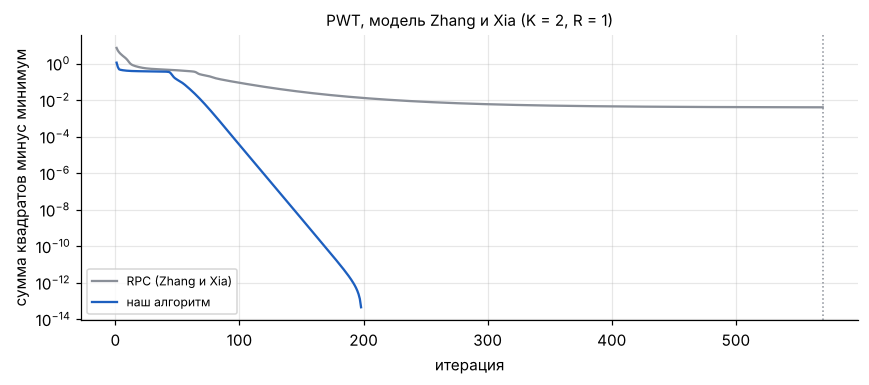

In [5]:
best = min(ours['hist'][-1], restart['hist'][-1])
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(np.arange(1, len(rpc5000['rss']) + 1), rpc5000['rss'] - best, color='#8a8f98', label='RPC (Zhang и Xia)')
ax.plot(np.arange(1, ours['iters'] + 1), ours['hist'] - best, color='#1d5fbf', label='наш алгоритм')
ax.axvline(int(rpc5000['info'].n_iter), color='#8a8f98', ls=':', lw=1)
ax.set_yscale('log'); ax.set_xlabel('итерация'); ax.set_ylabel('сумма квадратов минус минимум')
ax.set_title('PWT, модель Zhang и Xia (K = 2, R = 1)', fontsize=10); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4. Сравнение спецификаций по прогнозу

Схема как на данных Dominick's. Обучение — 1970–2009 ($T=40$), тест — 2010–2019. В тестовые годы страны случайно делятся пополам: для одной половины отклик известен, для другой его нужно предсказать. Факторы тестового года оцениваются по известной половине («с текущим годом»); во втором сценарии факторная часть не используется. Лаги отклика в признаках берутся фактические, то есть это прогноз на год вперёд для отложенных стран. Числа индексов и факторов выбираются по валидации на 2002–2009 при обучении на 1970–2001. Метрика — RMSE преобразованного отклика (в единицах его стандартного отклонения), 20 разбиений.

Модели:
- **без уровней** — спецификация Zhang и Xia (год среди признаков, факторы ортогональны году): малый ранг $(K,R)=(2,1)$ как у них, малый ранг с выбором по валидации и общие наклоны;
- **с уровнями $c_i$** — наша спецификация (год убран: общий для всех стран признак поглощается факторами): МНК по каждой стране с факторами, двусторонние эффекты, общие наклоны с факторами, жёсткий и мягкий малый ранг.

In [6]:
X = Xall[:, :, :10]; MASK = np.ones((N, T), bool)

def fit_spec(spec, Tf):
    kind, m, r = spec
    Yt, Xt, mt = Y[:, :Tf], X[:, :Tf], MASK[:, :Tf]
    if kind == 'zx':        R = fit_noc(Yt, Xall[:, :Tf], m, r, v[:Tf], tol=1e-12, max_iter=3000); return dict(B=R['B'], c=np.zeros(N), G=R['G'], noc=True)
    if kind == 'zx_common': return dict(fit_noc_common(Yt, Xall[:, :Tf], r, v[:Tf]), noc=True)
    if kind == 'twoway':    return pf.fit_twoway(Yt, Xt, mt)
    if kind == 'common':    return pf.fit(Yt, Xt, mt, 0, r, kind='common')
    H = pf.fit(Yt, Xt, mt, m, r)
    if kind == 'lr': return H
    return pf.fit_soft(Yt, Xt, mt, m, r, {'soft_eb': 'eb', 'soft_split': 'split'}[kind], hard=H)

def predict(M, Te, oc, use_factors=True):
    Xk = Xall[:, :Te] if M.get('noc') else X[:, :Te]
    base = np.einsum('itd,id->it', Xk, M['B']) + M['c'][:, None]; R = Y[:, :Te] - base; comp = np.zeros_like(base)
    if use_factors:
        for t in np.where(oc.any(0))[0]:
            o = oc[:, t]
            if M.get('kind') == 'twoway': comp[:, t] = R[o, t].mean()
            elif M['G'].shape[1]: comp[:, t] = M['G'] @ np.linalg.lstsq(M['G'][o], R[o, t], rcond=None)[0]
    return base + comp

def evaluate(models, Tf, Te, nsplit, rng, use_factors=True):
    out = {k: [] for k in models}
    for _ in range(nsplit):
        held = rng.random(N) < 0.5
        obs = MASK.copy(); obs[:, :Tf] = False; obs[:, Te:] = False
        tc, oc = (obs & held[:, None])[:, :Te], (obs & ~held[:, None])[:, :Te]
        for k, M in models.items():
            out[k].append(np.sqrt(np.mean((Y[:, :Te] - predict(M, Te, oc, use_factors))[tc] ** 2)))
    return {k: float(np.mean(v_)) for k, v_ in out.items()}

t0 = time.time()
rng = np.random.default_rng(2026)
grid = {f'lr_m{m}_r{r}': ('lr', m, r) for m in (1, 2, 3, 10) for r in (0, 1, 2, 3)}
grid.update({f'common_r{r}': ('common', 0, r) for r in (0, 1, 2, 3)})
grid.update({f'zx_m{m}_r{r}': ('zx', m, r) for m in (1, 2, 3) for r in (1, 2, 3)})
grid.update({f'zxc_r{r}': ('zx_common', 0, r) for r in (1, 2, 3)})
val = evaluate({k: fit_spec(s, 32) for k, s in grid.items()}, 32, 40, 5, rng)
pick = lambda pre: min([k for k in val if k.startswith(pre)], key=val.get)
b_lr = min([k for k in val if k.startswith('lr_') and not k.startswith('lr_m10')], key=val.get)
m_b, r_b = grid[b_lr][1], grid[b_lr][2]
final = {'без уровней: малый ранг (K=2, R=1)': ('zx', 2, 1), 'без уровней: малый ранг (валидация)': grid[pick('zx_m')],
         'без уровней: общие наклоны': grid[pick('zxc')],
         'с уровнями: МНК + факторы': grid[pick('lr_m10')], 'с уровнями: двусторонние эффекты': ('twoway', 0, 0),
         'с уровнями: общие наклоны + факторы': grid[pick('common')], 'с уровнями: жёсткая': ('lr', m_b, r_b),
         'с уровнями: мягкая (ЭБ)': ('soft_eb', m_b, r_b), 'с уровнями: мягкая (половины)': ('soft_split', m_b, r_b)}
models = {k: fit_spec(s, 40) for k, s in final.items()}
test = evaluate(models, 40, T, 20, rng); test0 = evaluate(models, 40, T, 20, np.random.default_rng(7), use_factors=False)
print(f'время: {time.time() - t0:.0f} с')
tab = pd.DataFrame({'(m или K, r)': [f'({s[1]}, {s[2]})' if s[0] != 'twoway' else '—' for s in final.values()],
                    'RMSE, с текущим годом': list(test.values()), 'RMSE, без текущего года': list(test0.values())}, index=list(final.keys()))
S, Sp = models['с уровнями: мягкая (ЭБ)'], models['с уровнями: мягкая (половины)']
print(f"мягкая: kappa ЭБ = {S['kappa']:.4f}, tau^2 ЭБ = {S['tau2']:.3f} (доля настоящих отклонений {S['share']:.2f}), tau^2 по половинам = {Sp['tau2_split']:.3f}")
tab.round(4)

время: 18 с
мягкая: kappa ЭБ = 0.0018, tau^2 ЭБ = 0.694 (доля настоящих отклонений 0.68), tau^2 по половинам = 1.011


,"(m или K, r)","RMSE, с текущим годом","RMSE, без текущего года"
"без уровней: малый ранг (K=2, R=1)","(2, 1)",0.0721,0.0755
без уровней: малый ранг (валидация),"(1, 1)",0.0636,0.0670
без уровней: общие наклоны,"(0, 1)",0.0606,0.0643
с уровнями: МНК + факторы,"(10, 1)",0.2367,0.2164
с уровнями: двусторонние эффекты,—,0.1713,0.1815
с уровнями: общие наклоны + факторы,"(0, 1)",0.0678,0.0700
с уровнями: жёсткая,"(1, 2)",0.1015,0.1253
с уровнями: мягкая (ЭБ),"(1, 2)",0.2045,0.2709
с уровнями: мягкая (половины),"(1, 2)",0.2098,0.2880


## Итоги

1. **Их результат воспроизводится точно:** нагрузки индексов, сингулярные числа и $R^2$ совпадают с их статьёй.
2. **Их алгоритм останавливается раньше минимума.** С их настройкой (200 итераций) сумма квадратов остатков 9.1511, без лимита алгоритм останавливается на 570-й итерации на 9.1420. Наш алгоритм за 198 итераций и 0.4 с приходит к 9.1379. Если запустить его из их точки, сумма квадратов уменьшается уже на первой итерации, и он приходит туда же. Значит, их точка — не минимум. Причина в правиле остановки по абсолютному изменению суммы квадратов ($10^{-6}$) при медленной сходимости чередования по остаткам: оно выходит на плато, не дойдя до минимума. Разница существенная: наклоны отличаются на 3.8% (6.8% с их настройкой), синус угла между подпространствами индексов 0.10 (0.17).
3. **По прогнозу лучше спецификации без индивидуальных уровней.** Среди признаков есть лаги отклика, а фиксированные эффекты при $T=40$ дают известное смещение динамической панели. Лучший результат — общие наклоны с одним фактором (RMSE 0.061). Малый ранг с выбором по валидации ($K=R=1$) даёт 0.064, выбор авторов $(2,1)$ — 0.072. Неоднородность наклонов в этой макропанели прогнозу не помогает.
4. **Мягкий малый ранг здесь неприменим в текущем виде.** Обе оценки $\tau^2$ находят огромные отклонения (доля 0.68). Они опираются на несмещённость МНК по каждой стране, а с лагом отклика среди признаков этого нет: смещение МНК одинаково в обеих половинах ряда и принимается за отклонения. В динамических панелях $\kappa$ нужно выбирать валидацией.